# Fusion-Based Quantum Computing
## Entanglement Swapping, Loss-Aware Resource Accounting, and Graph-State Fusion Branches

This notebook examines small photonic entangled resources through exact Bell-state projections and phenomenological preparation models. The first eight parts analyze entanglement swapping, independent photon loss, heralded acceptance, endpoint phase errors, resource consumption, and Monte Carlo estimation. **Part 9** extends the state-level calculation to destructive Bell measurements on two three-qubit graph resources, explicitly resolving successful and illustrative failure instruments.

The distinction between a quantum-state measurement and an externally assigned optical herald probability is maintained throughout. Neither calculation is a device-calibrated linear-optical fusion gate or a fault-tolerant photonic architecture simulation.


### Computational environment

The notebook is self-contained: the reference functions are defined below rather than imported from a separate Python package. Install `numpy`, `matplotlib`, `networkx`, and `jupyterlab` (or use an equivalent Jupyter environment), select the Python kernel, and run all cells in order.

Figures and the parameter-sweep CSV are written to the locally created `figures/` directory. All random sampling uses fixed seeds so the plotted examples are reproducible.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Relative output location, independent of the local machine or workspace.
FIGURES = Path('figures')
FIGURES.mkdir(parents=True, exist_ok=True)
print('Results directory:', FIGURES)
print('NumPy version:', np.__version__)


Results directory: figures
NumPy version: 2.3.5


### Reference functions

The following cell contains the numerical routines used by the baseline model: Bell-state preparation and corrections, analytic resource accounting, Monte Carlo sampling, and parallel-attempt probabilities. The functions are included directly to keep this notebook runnable without a separate `src/` directory.

In [2]:
"""Loss-aware, heralded Bell-pair-chain entanglement swapping model.

This models ideal Bell measurements and an abstract heralded success event.
It is NOT a hardware-calibrated linear-optical fusion gate.
"""
from dataclasses import dataclass

I = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
PHI = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)


def bell_state(a: int, b: int) -> np.ndarray:
    """|beta_ab> = (I tensor X^b Z^a)|Phi+>, a,b in {0,1}."""
    if a not in (0, 1) or b not in (0, 1):
        raise ValueError("Bell labels must be binary")
    op = np.linalg.matrix_power(X, b) @ np.linalg.matrix_power(Z, a)
    return np.kron(I, op) @ PHI


def swap_conditional(a: int, b: int):
    """Project B,C of |Phi+>_AB |Phi+>_CD onto Bell outcome a,b.

    Return outcome probability and normalized feed-forward-corrected AD state.
    """
    psi = np.kron(PHI, PHI).reshape(2, 2, 2, 2)  # A,B,C,D
    bra_bc = bell_state(a, b).conj().reshape(2, 2)
    post_ad = np.einsum('bc,abcd->ad', bra_bc, psi).reshape(4)
    probability = float(np.vdot(post_ad, post_ad).real)
    if probability <= 0:
        raise ValueError("Zero-probability outcome")
    post_ad /= np.sqrt(probability)
    correction = np.linalg.matrix_power(X, b) @ np.linalg.matrix_power(Z, a)
    corrected = np.kron(I, correction) @ post_ad
    return probability, corrected


def bell_fidelity_after_z_noise(p: float) -> float:
    """Independent Z flips on two endpoint qubits: even parity preserves Phi+."""
    if not 0 <= p <= 1:
        raise ValueError("p must be between zero and one")
    return (1 - p)**2 + p**2


@dataclass(frozen=True)
class Model:
    links: int = 3
    eta: float = 0.9
    herald: float = 0.5
    phase_error: float = 0.02

    def __post_init__(self):
        if not isinstance(self.links, int) or self.links < 1:
            raise ValueError("links must be a positive integer")
        for name in ("eta", "herald", "phase_error"):
            value = getattr(self, name)
            if not 0 <= value <= 1:
                raise ValueError(f"{name} must lie between zero and one")

    @property
    def photons(self) -> int:
        return 2 * self.links

    @property
    def fusions(self) -> int:
        return self.links - 1

    @property
    def success_probability(self) -> float:
        return self.eta**self.photons * self.herald**self.fusions

    @property
    def conditional_fidelity(self) -> float:
        return bell_fidelity_after_z_noise(self.phase_error)

    @property
    def weighted_overlap(self) -> float:
        return self.success_probability * self.conditional_fidelity

    @property
    def photons_per_accepted_output(self) -> float:
        p = self.success_probability
        return self.photons / p if p > 0 else np.inf


def simulate(model: Model, trials: int = 100_000, seed: int = 42):
    """Simulate all-photons-required Bell-pair-chain swapping attempts.

    Each chain attempt supplies 2*links photons. Each intermediate Bell
    measurement has independent abstract heralding success with probability h.
    Output Z errors on the two surviving endpoints are sampled independently.
    """
    if not isinstance(trials, int) or trials <= 0:
        raise ValueError("trials must be a positive integer")
    rng = np.random.default_rng(seed)
    survival = (rng.random((trials, model.photons)) < model.eta).all(axis=1)
    heralding = (rng.random((trials, model.fusions)) < model.herald).all(axis=1)
    accepted = survival & heralding
    errors = rng.random((trials, 2)) < model.phase_error
    target_overlap = ~(errors[:, 0] ^ errors[:, 1])
    weighted = accepted & target_overlap
    count = int(accepted.sum())
    p_hat = float(accepted.mean())
    fidelity = float(weighted.sum() / count) if count else float('nan')
    q_hat = float(weighted.mean())
    return dict(
        trials=trials, accepted=count, p_success=p_hat,
        conditional_fidelity=fidelity, weighted_overlap=q_hat,
        se_success=float(np.sqrt(p_hat * (1 - p_hat) / trials)),
        se_fidelity=(float(np.sqrt(fidelity * (1 - fidelity) / count))
                     if count else float('nan')),
    )


def multiplexed_round_probability(p_attempt: float, parallel_attempts: int):
    """Probability that at least one of K independent attempts succeeds."""
    if not 0 <= p_attempt <= 1 or not isinstance(parallel_attempts, int) or parallel_attempts < 1:
        raise ValueError("Invalid parameters")
    return 1 - (1 - p_attempt)**parallel_attempts



---
# Part 1 — Resource states and graph-state foundations

A **resource state** is a prepared entangled state consumed or processed by later measurements. The simplest example is a Bell pair:

$$|\Phi^+\rangle=\frac{|00\rangle+|11\rangle}{\sqrt2}.$$

Its stabilizer generators are $X\otimes X$ and $Z\otimes Z$:

$$ (X\otimes X)|\Phi^+\rangle=|\Phi^+\rangle,\qquad (Z\otimes Z)|\Phi^+\rangle=|\Phi^+\rangle.$$

A GHZ state is another small resource: $|\mathrm{GHZ}_3\rangle=(|000\rangle+|111\rangle)/\sqrt2$.

**Physical interpretation:** prepared resource states can later be joined through entangling measurements. The simple Bell-pair chain studied here creates *remote entanglement* after consuming intermediate photons; it does **not** increase the number of entangled surviving qubits.

In [3]:
XX = np.kron(X, X)
ZZ = np.kron(Z, Z)
assert np.isclose(np.vdot(PHI, PHI), 1.0)
assert np.allclose(XX @ PHI, PHI)
assert np.allclose(ZZ @ PHI, PHI)
GHZ3 = np.zeros(8, dtype=complex)
GHZ3[0] = GHZ3[-1] = 1 / np.sqrt(2)
assert np.isclose(np.vdot(GHZ3, GHZ3), 1.0)
print('Bell state normalized and stabilized by XX, ZZ.')
print('Three-qubit GHZ amplitudes:', GHZ3)

Bell state normalized and stabilized by XX, ZZ.
Three-qubit GHZ amplitudes: [0.70710678+0.j 0.        +0.j 0.        +0.j 0.        +0.j
 0.        +0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]


## Stabilizer verification

The computed Bell-state observables satisfy $\langle\Phi^+|XX|\Phi^+\rangle=\langle\Phi^+|ZZ|\Phi^+\rangle=1$. The GHZ-state generator checks below provide a second reference case.

In [4]:
XXX = np.kron(np.kron(X, X), X)
ZZI = np.kron(np.kron(Z, Z), I)
IZZ = np.kron(np.kron(I, Z), Z)
for observable in (XXX, ZZI, IZZ):
    assert np.allclose(observable @ GHZ3, GHZ3)
print('GHZ stabilizers validated.')

GHZ stabilizers validated.


---
# Part 2 — Bell and parity measurements

The four Bell states form an orthonormal basis:

$$|\Phi^{\pm}\rangle=\frac{|00\rangle\pm|11\rangle}{\sqrt2},\qquad
|\Psi^{\pm}\rangle=\frac{|01\rangle\pm|10\rangle}{\sqrt2}.$$

We label them by $a,b\in\{0,1\}$ using

$$|\beta_{ab}\rangle=(I\otimes X^b Z^a)|\Phi^+\rangle.$$

The commuting parity operators $XX$ and $ZZ$ have joint eigenvalues $(-1)^a$ and $(-1)^b$ respectively. Ideal Bell measurements distinguish all four outcomes mathematically, whereas a simple passive linear-optical analyzer does **not necessarily** identify every Bell outcome.

In [5]:
bell_labels = {(0,0): 'Phi+', (1,0): 'Phi-',
               (0,1): 'Psi+', (1,1): 'Psi-'}
vectors = []
for a,b in bell_labels:
    v = bell_state(a,b)
    vectors.append(v)
    xx = np.vdot(v, XX @ v).real
    zz = np.vdot(v, ZZ @ v).real
    assert np.isclose(xx, (-1)**a)
    assert np.isclose(zz, (-1)**b)
    print(f'{bell_labels[(a,b)]:5s}: <XX>={xx:+.0f}, <ZZ>={zz:+.0f}')
overlap = np.stack(vectors) @ np.stack(vectors).conj().T
assert np.allclose(overlap, np.eye(4))
assert np.allclose(XX @ ZZ, ZZ @ XX)
print('All Bell states orthonormal; parity measurements commute.')

Phi+ : <XX>=+1, <ZZ>=+1
Phi- : <XX>=-1, <ZZ>=+1
Psi+ : <XX>=+1, <ZZ>=-1
Psi- : <XX>=-1, <ZZ>=-1
All Bell states orthonormal; parity measurements commute.


## Bell projectors and the Born rule
For the ideal projectors $\Pi_{ab}=|\beta_{ab}\rangle\langle\beta_{ab}|$ we have $\sum_{a,b}\Pi_{ab}=I_4$. For a density matrix $\rho$,

$$P(a,b)=\mathrm{Tr}(\Pi_{ab}\rho).$$

The calculation below verifies projector completeness and the Born-rule probabilities for the maximally mixed state $I_4/4$.

In [6]:
projectors = [np.outer(v, v.conj()) for v in vectors]
assert np.allclose(sum(projectors), np.eye(4))
rho_mixed = np.eye(4)/4
probs = [np.trace(P @ rho_mixed).real for P in projectors]
assert np.allclose(probs, [0.25]*4)
print('Bell measurement probabilities for I/4:', probs)

Bell measurement probabilities for I/4: [np.float64(0.24999999999999994), np.float64(0.24999999999999994), np.float64(0.24999999999999994), np.float64(0.24999999999999994)]


---
# Part 3 — Entanglement swapping, fusion, and failure branches

Prepare two independent Bell pairs, $AB$ and $CD$:

$$|\Omega\rangle=|\Phi^+\rangle_{AB}\otimes|\Phi^+\rangle_{CD}.$$

An **ideal Bell measurement** on $BC$ yields one of four outcomes, each with probability $1/4$. After conditioning on the outcome, the endpoint system $AD$ is the corresponding Bell state. A known Pauli-frame correction $X_D^b Z_D^a$ maps it to $|\Phi^+\rangle_{AD}$, up to global phase.

$$\bigl({}_{BC}\langle\beta_{ab}|\otimes I_{AD}\bigr)|\Omega\rangle
\propto |\beta_{ab}\rangle_{AD}.$$

The two measured middle photons are consumed. **A Bell-pair chain outputs one corrected endpoint Bell pair—not a larger four-qubit cluster.**

In [7]:
for a in (0,1):
    for b in (0,1):
        prob, corrected = swap_conditional(a,b)
        fidelity = abs(np.vdot(PHI, corrected))**2
        assert np.isclose(prob, .25)
        assert np.isclose(fidelity, 1)
        print(f'Bell outcome (a={a},b={b}): P={prob:.2f}, corrected fidelity={fidelity:.3f}')

Bell outcome (a=0,b=0): P=0.25, corrected fidelity=1.000
Bell outcome (a=0,b=1): P=0.25, corrected fidelity=1.000
Bell outcome (a=1,b=0): P=0.25, corrected fidelity=1.000
Bell outcome (a=1,b=1): P=0.25, corrected fidelity=1.000


## What is a *failed fusion*?
An ideal Bell projector, an experimentally *heralded* successful fusion, and photon *erasure* are distinct operations. A failed optical fusion need not be equivalent to deleting the measured qubits without acquiring information. The failure instrument might instead reveal, for example, computational-basis measurements on both middle qubits, yielding product endpoint states. **Different fusion devices have different failure instruments.**

In the baseline resource-accounting simulator, failed heralds cause a complete chain attempt to be **discarded**; this is a conscious simplification rather than a claim of universal non-recoverability.

In [8]:
# Explicit illustrative failure instrument: measure B and C in the Z basis.
# For the outcome B=0,C=0, the remaining A,D state is |00>, not a Bell pair.
psi_abcd = np.kron(PHI, PHI).reshape(2,2,2,2)
post_ad = psi_abcd[:,0,0,:].reshape(4)
prob_z00 = float(np.vdot(post_ad, post_ad).real)
post_ad /= np.sqrt(prob_z00)
assert np.isclose(prob_z00, 0.25)
assert np.allclose(post_ad, [1,0,0,0])
print('Illustrative failure measurement B=C=0:', 'probability', prob_z00,
      'endpoint state', post_ad.real)

Illustrative failure measurement B=C=0: probability 0.2499999999999999 endpoint state [1. 0. 0. 0.]


The local-$Z$ failure example leaves the endpoint pair separable even though the measurement outcome is known. A recorded failure pattern can retain classical information, but the recoverable resource depends on the specified measurement instrument.

---
# Part 4 — Photonic loss, erasure, and heralding

Let $L$ be the number of initial Bell-pair resources. The initial chain contains $2L$ photons and needs $L-1$ entanglement-swapping measurements. Our simplified all-or-nothing attempt assumes:

- each required photon is available independently with probability $\eta$;
- each fusion attempt reports success independently with probability $h$;
- every required photon and fusion must succeed; otherwise the whole attempt is discarded;
- conditional errors are applied to the **two final endpoint qubits**.

Thus the success probability is

$$\boxed{P_{\mathrm{accept}}=\eta^{2L}h^{L-1}.}$$

This is a idealized resource-preparation model, **not** a universal FBQC success law. Vacuum/erasure is distinct from the logical state $|0\rangle$ of a polarization-encoded photon.

In [9]:
model = Model(links=3, eta=0.95, herald=0.5, phase_error=0.03)
print('Initial photons:', model.photons)
print('Intermediate fusions:', model.fusions)
print('Analytical full-chain success:', round(model.success_probability, 6))
assert np.isclose(model.success_probability, .95**6 * .5**2)

Initial photons: 6
Intermediate fusions: 2
Analytical full-chain success: 0.183773


## Phase errors on the surviving Bell pair

Independent Pauli-$Z$ errors on the two endpoint qubits cancel if either zero or two flips occur. A single flip maps $|\Phi^+\rangle$ to the orthogonal $|\Phi^-\rangle$. Therefore

$$\boxed{F_{\mathrm{cond}}=(1-p)^2+p^2=1-2p+2p^2.}$$

The weighted target-state overlap per attempt is

$$Q=P_{\mathrm{accept}}F_{\mathrm{cond}}.$$

This is not a logical error-correction threshold or a task-success probability.

In [10]:
p = model.phase_error
assert np.isclose(bell_fidelity_after_z_noise(p), (1-p)**2 + p**2)
print('Conditional Bell fidelity:', model.conditional_fidelity)
print('Weighted target overlap:', model.weighted_overlap)
print('Two-flip cancellation: F(p=1) =', bell_fidelity_after_z_noise(1))

Conditional Bell fidelity: 0.9418
Weighted target overlap: 0.1730773856476562
Two-flip cancellation: F(p=1) = 1


---
# Part 5 — Exact numerical Bell-projection simulation

The reference implementation uses a four-qubit tensor with axes $A,B,C,D$, contracts it with a Bell-state bra on $BC$, normalizes the endpoint vector, and applies the measurement-dependent correction on $D$. This exact calculation is independent of the probabilistic heralding model.

The calculations above verified all four Bell outcomes. Here we inspect the **uncorrected** and corrected state to see the feed-forward action explicitly.

In [11]:
a,b = 1,1  # Psi- outcome
omega = np.kron(PHI, PHI).reshape(2,2,2,2)
raw = np.einsum('bc,abcd->ad', bell_state(a,b).conj().reshape(2,2), omega).reshape(4)
prob = np.vdot(raw, raw).real
raw = raw / np.sqrt(prob)
_, fixed = swap_conditional(a,b)
print('Uncorrected endpoint state:', np.round(raw.real, 5))
print('Corrected endpoint state:  ', np.round(fixed.real, 5))
print('Corrected fidelity:', abs(np.vdot(PHI, fixed))**2)
assert np.isclose(abs(np.vdot(PHI, fixed))**2, 1)

Uncorrected endpoint state: [ 0.       0.70711 -0.70711  0.     ]
Corrected endpoint state:   [-0.70711  0.       0.      -0.70711]
Corrected fidelity: 0.9999999999999996


## A density-matrix cross-check
Define $\rho_{AD}=|\psi_{AD}\rangle\langle\psi_{AD}|$. Verify its trace, purity, and Bell-state fidelity. The optional software tool Perceval can be used later to model a specified linear-optical circuit with documented detector patterns; the current baseline does not assert that Perceval simulates this complete heralded physical instrument.

In [12]:
rho_ad = np.outer(fixed, fixed.conj())
assert np.isclose(np.trace(rho_ad), 1)
assert np.isclose(np.trace(rho_ad @ rho_ad), 1)
assert np.isclose(np.vdot(PHI, rho_ad @ PHI).real, 1)
print('Endpoint density matrix trace, purity, fidelity: 1, 1, 1')

Endpoint density matrix trace, purity, fidelity: 1, 1, 1


---
# Part 6 — Resource accounting, retries, and multiplexing

For independent complete attempts, the waiting time $T$ for one accepted output is geometrically distributed:

$$\Pr(T=t)=(1-P_{\mathrm{accept}})^{t-1}P_{\mathrm{accept}},\quad
\mathbb E[T]=\frac1{P_{\mathrm{accept}}}.$$

If each attempt is supplied with all $2L$ input photons, then

$$R_{\mathrm{photons}}=\frac{2L}{P_{\mathrm{accept}}}.$$

With $K$ complete, independent parallel attempts per round,

$$P_{\ge1}(K)=1-(1-P_{\mathrm{accept}})^K.$$

Parallel copies increase round success but consume $2LK$ photons per fully provisioned round. If all copies are supplied, the expected photons per round with **at least one** success is $2LK/P_{\ge1}(K)$. This differs from cost per output if multiple successful copies are retained.

In [13]:
p_single = model.success_probability
for k in (1,2,3,5,10):
    p_round = multiplexed_round_probability(p_single,k)
    cost = (2*model.links*k)/p_round
    print(f'K={k:2d}  round success={p_round:.5f}  photons/positive round={cost:.2f}')
assert np.isclose(multiplexed_round_probability(p_single,1),p_single)

K= 1  round success=0.18377  photons/positive round=32.65
K= 2  round success=0.33377  photons/positive round=35.95
K= 3  round success=0.45621  photons/positive round=39.46
K= 5  round success=0.63771  photons/positive round=47.04
K=10  round success=0.86875  photons/positive round=69.06


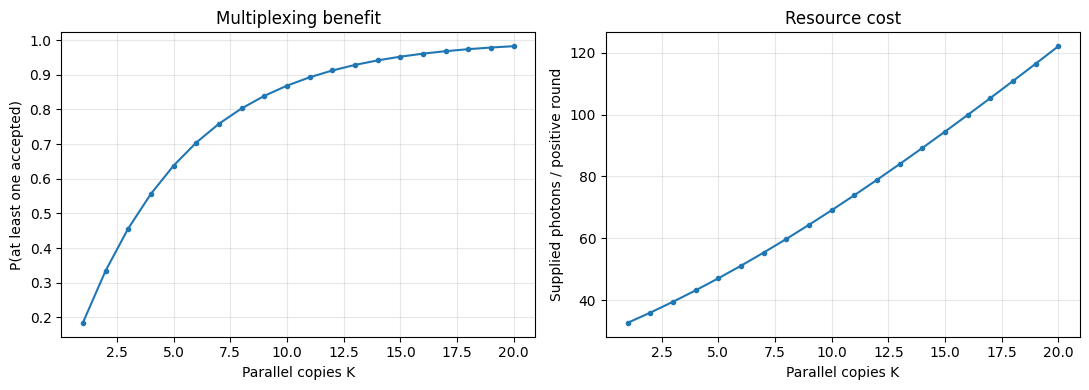

In [14]:
Kvals = np.arange(1, 21)
p_rounds = np.array([multiplexed_round_probability(p_single, int(k)) for k in Kvals])
photons_per_positive_round = 2*model.links*Kvals / p_rounds
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(Kvals,p_rounds,marker='o',markersize=3)
axes[0].set(xlabel='Parallel copies K', ylabel='P(at least one accepted)', title='Multiplexing benefit')
axes[1].plot(Kvals,photons_per_positive_round,marker='o',markersize=3)
axes[1].set(xlabel='Parallel copies K', ylabel='Supplied photons / positive round', title='Resource cost')
for ax in axes: ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIGURES/'multiplexing.png',dpi=150); plt.show()

## Parameter sensitivity
Logarithmic derivatives of the success law are

$$\frac{\partial\ln P_{\mathrm{accept}}}{\partial\ln\eta}=2L,\qquad
\frac{\partial\ln P_{\mathrm{accept}}}{\partial\ln s}=L-1.$$

These are **elasticities of our model**, not experimental measurements. The plot below compares the sensitivity to $\eta$ and $h$ across chain lengths.

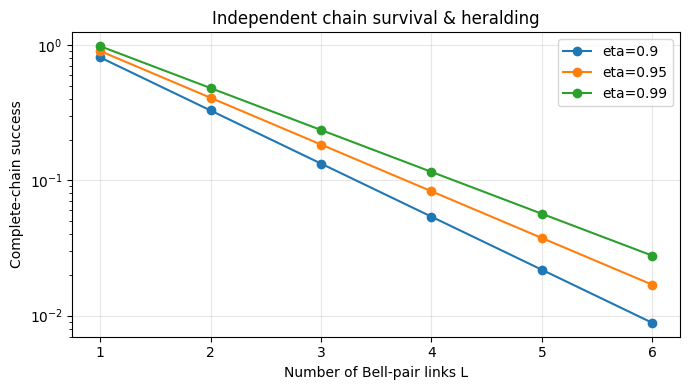

In [15]:
L_values = np.arange(1, 7)
fig,ax=plt.subplots(figsize=(7,4))
for eta in (0.9,0.95,0.99):
    vals = [Model(links=int(L),eta=eta,herald=.5).success_probability for L in L_values]
    ax.plot(L_values, vals, marker='o', label=f'eta={eta}')
ax.set(xlabel='Number of Bell-pair links L', ylabel='Complete-chain success',
       title='Independent chain survival & heralding')
ax.set_yscale('log'); ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES/'link_scaling.png',dpi=150); plt.show()

---
# Part 7 — Monte Carlo, statistical uncertainty, and validation

Each Monte Carlo trial samples $2L$ photon-survival flags and $L-1$ heralding flags. If accepted, the endpoint Bell pair is subjected to two independent $Z$ errors. Its overlap is one when the number of endpoint errors is even, zero otherwise.

Define binary indicators $A_m$ for accepted attempts and $C_m$ for accepted attempts with unit target overlap:

$$\widehat P_{\mathrm{accept}}=\frac1M\sum_m A_m,\qquad
\widehat F_{\mathrm{cond}}=\frac{\sum_m C_m}{\sum_m A_m},\qquad
\widehat Q=\frac1M\sum_m C_m.$$

If no attempt succeeds, $\widehat F_{\mathrm{cond}}$ is **undefined** (NaN), not zero.

For Bernoulli estimates, the standard error is $\widehat{\mathrm{SE}}=\sqrt{\widehat r(1-\widehat r)/n}$. For conditional fidelity, use $n=N_{\mathrm{accepted}}$, not all trials.

In [16]:
result = simulate(model, trials=200_000, seed=123)
for key in (
    'accepted', 'p_success', 'conditional_fidelity',
    'weighted_overlap', 'se_success', 'se_fidelity',
):
    value = result[key]
    value = int(value) if key == 'accepted' else float(value)
    print(f'{key:22s}: {value}')
assert abs(result['p_success'] - model.success_probability) < 5 * np.sqrt(
    model.success_probability * (1 - model.success_probability) / result['trials']
)
assert abs(result['conditional_fidelity'] - model.conditional_fidelity) < 5 * np.sqrt(
    model.conditional_fidelity * (1 - model.conditional_fidelity) / result['accepted']
)
print('Monte Carlo consistent with both analytical predictions.')


accepted              : 36679
p_success             : 0.183395
conditional_fidelity  : 0.9435099103028981
weighted_overlap      : 0.173035
se_success            : 0.0008653359866982305
se_fidelity           : 0.001205453943083897
Monte Carlo consistent with both analytical predictions.


## Convergence experiment
Repeat with increasing trial counts and plot analytical predictions and approximate $95\%$ normal-error bars. These intervals can be poor when events are rare or the estimate is near 0 or 1; use Wilson or exact binomial intervals in that regime. Individual realizations do not necessarily improve monotonically.

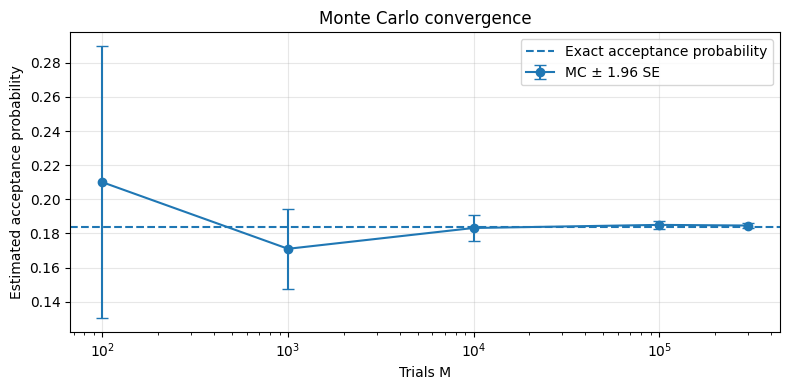

In [17]:
sizes = np.array([100, 1_000, 10_000, 100_000, 300_000])
runs = [
    simulate(model, trials=int(sample_size), seed=123 + i)
    for i, sample_size in enumerate(sizes)
]
means = np.array([run['p_success'] for run in runs])
errors = np.array([run['se_success'] for run in runs])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(sizes, means, yerr=1.96 * errors, fmt='o-', capsize=4,
            label='MC ± 1.96 SE')
ax.axhline(model.success_probability, ls='--',
           label='Exact acceptance probability')
ax.set(xscale='log', xlabel='Trials M', ylabel='Estimated acceptance probability',
       title='Monte Carlo convergence')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / 'convergence.png', dpi=150)
plt.show()


## Deterministic edge-case tests
We check perfect components, complete loss, error-parity cancellation, and zero-success handling. These catch implementation defects that stochastic convergence alone cannot identify.

In [18]:
perfect=simulate(Model(links=2,eta=1,herald=1,phase_error=0),trials=1000)
assert perfect['p_success']==perfect['conditional_fidelity']==perfect['weighted_overlap']==1
lost=simulate(Model(links=2,eta=0,herald=1),trials=1000)
assert lost['accepted']==0 and np.isnan(lost['conditional_fidelity'])
assert bell_fidelity_after_z_noise(1)==1  # two Z flips cancel
assert bell_fidelity_after_z_noise(.5)==.5
print('Deterministic edge cases validated.')

Deterministic edge cases validated.


---
# Part 8 — Integrated parameter study

### Parameter sweep
Compare loss-aware entanglement-swapping chains across $L$, $\eta$, $s$ and $p$. Report separately:

1. Exact and sampled acceptance probability;
2. conditional output Bell fidelity;
3. probability-weighted target overlap;
4. expected complete attempts and supplied photons per accepted output;
5. effects of independent parallel copies;
6. uncertainty and limitations.

**Scientific boundary:** This baseline consumes pairs and leaves a corrected *two-qubit* Bell state. It does **not** model scalable multi-qubit graph-state growth, a realistic linear-optical fusion POVM, a spin–photon emitter, or fault-tolerant computation.

In [19]:
# Final experiment: well-defined, reproducible parameter sweep.
params = [
    Model(links=L, eta=eta, herald=0.5, phase_error=0.03)
    for L in (2,3,4)
    for eta in (0.90,0.95,0.99)
]
records=[]
for ix,m in enumerate(params):
    r=simulate(m, trials=50_000, seed=2026+ix)
    records.append((m.links,m.eta,m.success_probability,r['p_success'],
                    m.conditional_fidelity,r['conditional_fidelity'],
                    m.photons_per_accepted_output))
print(f"{'L':>2} {'eta':>5} {'P exact':>9} {'P MC':>9} {'F exact':>9} {'F MC':>9} {'photons/out':>12}")
for L,eta,pex,pmc,fex,fmc,cost in records:
    print(f'{L:2d} {eta:5.2f} {pex:9.5f} {pmc:9.5f} {fex:9.5f} {fmc:9.5f} {cost:12.1f}')

 L   eta   P exact      P MC   F exact      F MC  photons/out
 2  0.90   0.32805   0.32820   0.94180   0.94022         12.2
 2  0.95   0.40725   0.40840   0.94180   0.94398          9.8
 2  0.99   0.48030   0.47780   0.94180   0.94240          8.3
 3  0.90   0.13286   0.13212   0.94180   0.94460         45.2
 3  0.95   0.18377   0.18142   0.94180   0.94003         32.6
 3  0.99   0.23537   0.23688   0.94180   0.94132         25.5
 4  0.90   0.05381   0.05352   0.94180   0.94283        148.7
 4  0.95   0.08293   0.08480   0.94180   0.93797         96.5
 4  0.99   0.11534   0.11364   0.94180   0.93488         69.4


In [20]:
# Export results in a portable, dependency-free CSV.
import csv
out=FIGURES/'final_experiment.csv'
with out.open('w',newline='') as f:
    w=csv.writer(f)
    w.writerow(['links','eta','p_exact','p_monte_carlo','f_exact','f_monte_carlo','photons_per_accepted'])
    w.writerows(records)
print('Saved:', out)

Saved: figures/final_experiment.csv


## Scientific conclusions and limitations

- The all-or-nothing model predicts $P_{\mathrm{accept}}=\eta^{2L}h^{L-1}$, so success drops with chain length when $\eta,s<1$.
- Under the specified **output-only** independent phase-flip model, conditional Bell fidelity is $(1-p)^2+p^2$ and is independent of chain length. **This is an assumption**, not a general physical claim about long chains.
- Multiplexing increases the probability of at least one successful output per time window but consumes more fully provisioned input resources.
- The baseline samples herald outcomes as **binary flags**, not a physically specified optical measurement instrument. It discards unsuccessful chains without simulating their quantum residual states.
- Entanglement swapping consumes the middle qubits and leaves only the distant Bell pair. Multi-qubit graph-state *growth* requires additional resource shapes and fusion rules.

### Remaining physical modelling requirements

An experimentally predictive treatment would require a specified optical measurement instrument, realistic detector patterns and photon indistinguishability, source noise, and temporal scheduling. The next section addresses one narrower issue: it evaluates state-dependent Bell-measurement branches on higher-valence resources rather than treating every successful operation solely as a Bernoulli flag.


## Validation checklist

- [x] Bell-basis orthonormality, $XX/ZZ$ parity eigenvalues, projector completeness
- [x] All four entanglement-swapping outcomes and Pauli-frame corrections
- [x] Example failure-measurement branch resulting in a product state
- [x] Closed-form photon survival / heralding / endpoint dephasing
- [x] Monte Carlo estimates with statistical errors and convergence plots
- [x] Multiplexing and expected resource-overhead analysis
- [x] In-notebook numerical consistency and deterministic-limit checks
- [x] Reproducible parameters, random seeds, and figure exports

### Further reading
S. Bartolucci et al., *Fusion-based quantum computation*, Nature Communications 14, 912 (2023), DOI: 10.1038/s41467-023-36493-1.  
D. E. Browne and T. Rudolph, *Resource-efficient linear optical quantum computation*, Phys. Rev. Lett. 95, 010501 (2005), DOI: 10.1103/PhysRevLett.95.010501.  
R. Raussendorf and H. J. Briegel, *A one-way quantum computer*, Phys. Rev. Lett. 86, 5188 (2001), DOI: 10.1103/PhysRevLett.86.5188.

### Extension

Part 9 below studies an explicit two-resource Bell projection and a distinct local-measurement failure instrument. It is a complementary state-level model: the original chain statistics are not automatically propagated into its four-qubit output density matrix.


---
# Part 9 — Explicit Measurement Branches Between Graph Resources

## Motivation

The baseline model treats heralding as an independent Bernoulli event and models only Bell-pair-chain swapping. It therefore does not calculate the quantum state left after successful or failed fusion operations on larger resources. Here, two independent three-qubit graph states are joined by a destructive Bell measurement on one photon from each resource, with all four outcome branches retained.

For comparison, a separate pair of local $Z$ measurements is used as a **specified failure instrument**. Quantum-state projections are calculated exactly; photon survival and herald selection remain independent external probabilities. The result is a small-state example of measurement-induced inter-resource entanglement, not a physical implementation of a Type-I or Type-II linear-optical fusion gate.

The functions below initialize their own resource states and measurement definitions. They do not reuse the baseline model's noise or herald parameters.

In [21]:
import networkx as nx


def graph_state(graph: nx.Graph) -> np.ndarray:
    """Ideal graph state in big-endian tensor order q0, q1, ..., q(n-1).

    Basis index bits are read from most significant to least significant,
    matching np.kron and the tensor-axis contractions used below.
    """
    n = graph.number_of_nodes()
    if set(graph.nodes) != set(range(n)):
        raise ValueError('Graph nodes must be consecutive integers 0, ..., n-1')

    state = np.ones(2**n, dtype=complex) / np.sqrt(2**n)
    for index in range(2**n):
        parity = sum(
            ((index >> (n - 1 - i)) & 1) * ((index >> (n - 1 - j)) & 1)
            for i, j in graph.edges()
        ) % 2
        if parity:
            state[index] *= -1
    return state


# An asymmetric labelled graph distinguishes big- from little-endian indexing.
asymmetric_graph = nx.Graph([(0, 1), (0, 2)])
asymmetric_state = graph_state(asymmetric_graph)
assert np.isclose(asymmetric_state[0b110], -1 / np.sqrt(8))
assert np.isclose(asymmetric_state[0b011], +1 / np.sqrt(8))

# Independent stabilizer checks fix the labels of all three qubits.
for generator in (
    np.kron(np.kron(X, Z), Z),
    np.kron(np.kron(Z, X), I),
    np.kron(np.kron(Z, I), X),
):
    assert np.allclose(generator @ asymmetric_state, asymmetric_state)

bell_vectors = [bell_state(a, b) for a in (0, 1) for b in (0, 1)]
bell_matrix = np.column_stack(bell_vectors)
assert np.allclose(bell_matrix.conj().T @ bell_matrix, np.eye(4))
print('Big-endian graph-state indexing checked on an asymmetric graph.')


Big-endian graph-state indexing checked on an asymmetric graph.


## 9.1 Bell-projection branches on graph resources
Start with separate 3-qubit chains $G_A:0-1-2$ and $G_B:3-4-5$. Perform a Bell measurement on qubits $2,3$. Conditional on outcome $(a,b)$, the remaining four-qubit state is
$$
|\psi_{ab}\rangle\propto {}_{2,3}\langle\beta_{ab}| (|G_A\rangle\otimes|G_B\rangle).
$$
In the implementation, all tensor axes are **explicitly ordered** by qubit labels $0,1,2,3,4,5$, avoiding Qiskit's reversed label convention. Projective Bell measurement outcomes sum to probability one. A separate optical herald probability would have to be supplied by the experiment or a photonic circuit simulation.


In [22]:
# Qubits q0, q1, q2 and q3, q4, q5 occupy the two input resources.
state_a = graph_state(nx.path_graph(3))
state_b = graph_state(nx.path_graph(3))
joint_state = np.kron(state_a, state_b).reshape((2,) * 6)


def bell_branch(a: int, b: int):
    """Project q2, q3; return (Born probability, normalized q0,q1,q4,q5)."""
    bell_bra = bell_state(a, b).conj().reshape(2, 2)
    unnormalized = np.einsum('cd,abcdef->abef', bell_bra, joint_state).reshape(-1)
    probability = float(np.vdot(unnormalized, unnormalized).real)
    if probability <= 0:
        raise ValueError('Zero-probability Bell branch')
    return probability, unnormalized / np.sqrt(probability)


branches = {(a, b): bell_branch(a, b) for a in (0, 1) for b in (0, 1)}
print('Bell outcome probabilities:')
for label, (probability, _) in branches.items():
    print(label, f'{probability:.6f}')
assert np.isclose(sum(item[0] for item in branches.values()), 1.0)
assert all(np.isclose(np.vdot(item[1], item[1]), 1.0)
           for item in branches.values())


Bell outcome probabilities:
(0, 0) 0.250000
(0, 1) 0.250000
(1, 0) 0.250000
(1, 1) 0.250000


## 9.2 Entanglement across the resource cut
Test entanglement across the cut $(q_0,q_1)|(q_4,q_5)$. If the two original resources were independent, this cut had zero entanglement entropy. After a Bell projection, a nonzero reduced-state von Neumann entropy proves that the surviving subsystems are entangled.
$$
S(\rho_L)=-\mathrm{Tr}(\rho_L\log_2\rho_L).
$$
This proves a useful quantum connection, but **does not by itself certify** that the output is an intended graph state up to local Clifford corrections.


In [23]:
def entropy_left(state4: np.ndarray) -> float:
    """Von Neumann entropy of the q0,q1 subsystem (in bits)."""
    psi = state4.reshape(4, 4)
    rho_left = psi @ psi.conj().T
    eigenvalues = np.linalg.eigvalsh(rho_left)
    nonzero = eigenvalues[eigenvalues > 1e-12]
    return -float(np.sum(nonzero * np.log2(nonzero)))


entropies = [entropy_left(state) for _, state in branches.values()]
print('Entanglement entropy for four outcomes:', np.round(entropies, 6))
assert all(np.isclose(value, 1.0) for value in entropies)


Entanglement entropy for four outcomes: [1. 1. 1. 1.]


### 9.2.1 Output-state structure: GHZ and a rotated Bell projection

Nonzero entanglement entropy across the resource cut does not identify the resulting graph-state class. For the $(a,b)=(0,0)$ **ordinary Bell projection** on $q_2,q_3$, the surviving state on $(q_0,q_1,q_4,q_5)$ is locally equivalent to a four-qubit GHZ state. Specifically, applying Hadamard gates to the two outer surviving qubits produces

$$
(H_{0}\otimes I_{1}\otimes I_{4}\otimes H_{5})|\psi_{00}\rangle
=\frac{|0000\rangle+|1111\rangle}{\sqrt{2}},
$$

up to an irrelevant global phase. This is **not** the four-qubit linear-cluster state.

For comparison, applying $H$ to $q_3$ **before** the Bell projection changes the measured observables to $X_2 Z_3$ and $Z_2 X_3$. For the $(0,0)$ outcome, the normalized residual state equals the path-graph state on $(0,1,4,5)$. These equalities are tested directly below. The rotated projector is an *ideal state-level measurement*; it is not by itself a specification of a physical linear-optical fusion apparatus.

In [24]:
H_local = (X + Z) / np.sqrt(2)


def tensor_product(operators):
    out = np.array([1.0], dtype=complex)
    for op in operators:
        out = np.kron(out, op)
    return out


# Ordinary Bell projection: output is local-H-equivalent to GHZ4.
ghz4 = np.zeros(16, dtype=complex)
ghz4[[0, 15]] = 1 / np.sqrt(2)
ordinary_output = branches[(0, 0)][1]
outer_h = tensor_product([H_local, I, I, H_local])
ghz_fidelity = float(abs(np.vdot(ghz4, outer_h @ ordinary_output))**2)
assert np.isclose(ghz_fidelity, 1.0)

# Rotated Bell projection: H on q3 prior to measuring q2,q3.
rotated_joint = np.moveaxis(
    np.tensordot(H_local, joint_state, axes=(1, 3)), 0, 3
)
rotated_unnormalized = np.einsum(
    'cd,abcdef->abef', PHI.conj().reshape(2, 2), rotated_joint
).reshape(-1)
rotated_output = rotated_unnormalized / np.linalg.norm(rotated_unnormalized)
path4 = graph_state(nx.path_graph(4))
path_fidelity = float(abs(np.vdot(path4, rotated_output))**2)
assert np.isclose(path_fidelity, 1.0)

print(f'Ordinary Bell outcome (0,0), local-H GHZ4 fidelity: {ghz_fidelity:.6f}')
print(f'Rotated Bell outcome (0,0), path-graph fidelity: {path_fidelity:.6f}')


Ordinary Bell outcome (0,0), local-H GHZ4 fidelity: 1.000000
Rotated Bell outcome (0,0), path-graph fidelity: 1.000000


## 9.3 A specified local-measurement failure instrument
For comparison only, replace the Bell measurement by separate $Z$-basis measurements of qubits 2 and 3. This models one *specified* destructive failure instrument; **it must not be advertised as the universal failure rule of an optical fusion gate.** The remaining two resources should stay separable across the original component cut.


In [25]:
def computational_branch(x: int, y: int):
    """Project q2 and q3 locally in Z; return residual resource state."""
    post = joint_state[:, :, x, y, :, :].reshape(16)
    probability = float(np.vdot(post, post).real)
    if probability <= 0:
        raise ValueError('Zero-probability computational branch')
    return probability, post / np.sqrt(probability)


failure_branches = {
    (x, y): computational_branch(x, y)
    for x in (0, 1) for y in (0, 1)
}
assert np.isclose(sum(item[0] for item in failure_branches.values()), 1.0)
assert all(abs(entropy_left(item[1])) < 1e-10
           for item in failure_branches.values())
print('Local-Z branches remain separable across the resource cut.')


Local-Z branches remain separable across the resource cut.


## 9.4 Heralded sampling and branch statistics
An **externally specified** herald probability $h$ chooses whether the Bell or local-$Z$ instrument is applied. Conditional branch probabilities follow the state-level Born rule. Optical photon survival is independently sampled. We report both the probability of an accepted four-qubit resource and its average bipartite entropy, not a fabricated logical fidelity.


h=0.25: sampled=0.1791, exact=0.1838, counts={(0, 0): 875, (0, 1): 890, (1, 0): 926, (1, 1): 891}
h=0.50: sampled=0.3626, exact=0.3675, counts={(0, 0): 1783, (0, 1): 1783, (1, 0): 1820, (1, 1): 1867}
h=0.75: sampled=0.5494, exact=0.5513, counts={(0, 0): 2722, (0, 1): 2718, (1, 0): 2733, (1, 1): 2816}


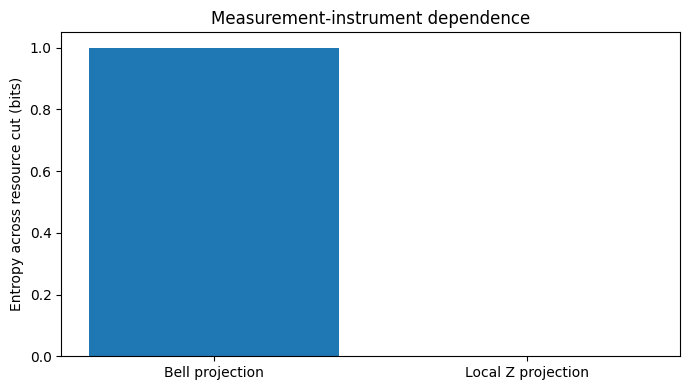

All extension checks passed.


In [26]:
def fusion_experiment(shots=20_000, eta=0.95, h=0.5, seed=4):
    """Sample independent photon survival, heralding, and Bell outcomes."""
    rng = np.random.default_rng(seed)
    alive = (rng.random((shots, 6)) < eta).all(axis=1)
    heralded = rng.random(shots) < h
    accepted = alive & heralded

    probabilities = np.array([item[0] for item in branches.values()])
    labels = list(branches)
    sampled = rng.choice(4, size=int(accepted.sum()), p=probabilities)
    counts = np.bincount(sampled, minlength=4)
    outcome_counts = {label: int(count) for label, count in zip(labels, counts)}
    return float(accepted.mean()), outcome_counts


shots = 20_000
eta_ext = 0.95
for herald_probability in (0.25, 0.50, 0.75):
    rate, counts = fusion_experiment(
        shots=shots, eta=eta_ext, h=herald_probability
    )
    expected = eta_ext**6 * herald_probability
    standard_error = np.sqrt(expected * (1 - expected) / shots)
    print(f'h={herald_probability:.2f}: sampled={rate:.4f}, '
          f'exact={expected:.4f}, counts={counts}')
    assert abs(rate - expected) < 5 * standard_error

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(['Bell projection', 'Local Z projection'], [
    float(np.mean(entropies)),
    float(np.mean([entropy_left(item[1]) for item in failure_branches.values()])),
])
ax.set_ylabel('Entropy across resource cut (bits)')
ax.set_title('Measurement-instrument dependence')
fig.tight_layout()
plt.show()
print('All extension checks passed.')


## 9.5 Interpretation and limitations
**Improved:** explicit four-outcome Bell-state projectors; actual quantum-state update on two small graph resources; failure branches explicitly separated from successes; normalized Born probabilities and entanglement validation.

**Not yet implemented:** linear-optical beam splitters, threshold or number-resolving detectors, distinguishability, physically correct Type-I/II fusion branches, feed-forward graph-state equivalence, large-scale resource growth. These would require a further specialist extension.

A full graph-state fusion protocol would additionally identify outcome-dependent local Clifford transformations and graph rewrite rules, then connect the resulting quantum states to an explicitly modelled optical instrument.


**Output-state identification:** the $(0,0)$ ordinary Bell branch is locally equivalent to GHZ$_4$, while the $(0,0)$ rotated Bell branch reproduces the four-qubit path graph. These are statevector comparisons, not optical-device simulations.
